In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset shape:", X.shape)
print("Target classes:", data.target_names)
print("First five rows:")
display(X.head())

Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']
First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 455
Testing records: 114


In [4]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000)
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!


In [5]:
results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted"
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted"
        ),
        "F1 Score": f1_score(
            y_test, y_pred, average="weighted"
        )
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9825,0.9825,0.9825,0.9825
1,Decision Tree,0.9123,0.9161,0.9123,0.9130


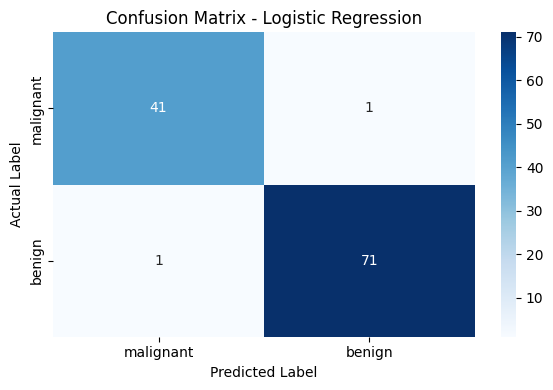

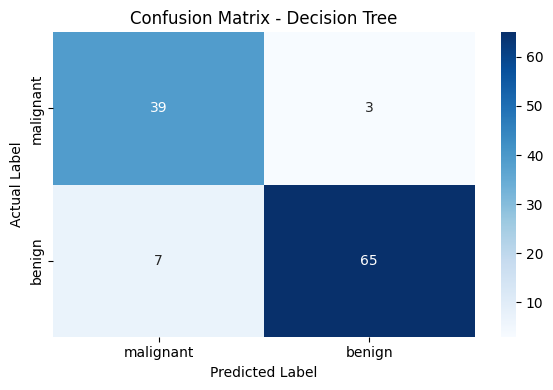

In [6]:
for name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=data.target_names,
        yticklabels=data.target_names
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

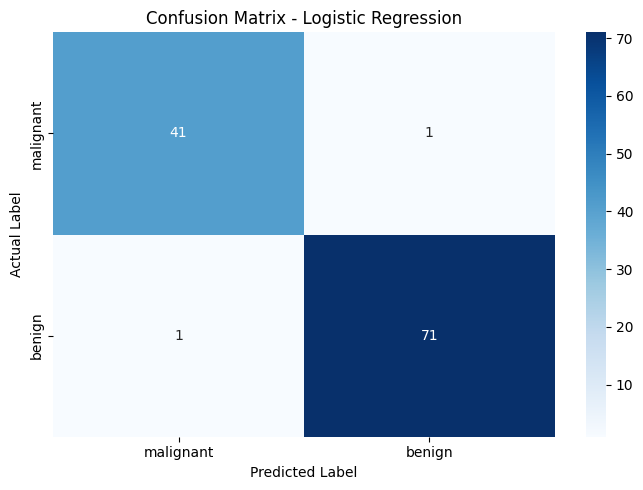

Confusion matrix saved successfully!


In [7]:
cm = confusion_matrix(
    y_test, predictions["Logistic Regression"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix saved successfully!")

In [8]:
best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(), "Model"
]

best_prediction = predictions[best_model_name]

malignant_recall = recall_score(
    y_test,
    best_prediction,
    pos_label=0
)

report = f"""
DAY 12 - MACHINE LEARNING MODEL EVALUATION

Dataset: Breast Cancer Wisconsin
Total records: {len(X)}
Training records: {len(X_train)}
Testing records: {len(X_test)}

MODEL PERFORMANCE
{results_df.round(4).to_string(index=False)}

Best model by weighted F1-score: {best_model_name}
Recall for malignant cases: {malignant_recall:.4f}

CONCLUSION
Accuracy measures overall correctness.
Precision measures the reliability of positive predictions.
Recall measures how many actual cases are identified.
F1-score balances precision and recall.

For this dataset, malignant-class recall is particularly
important because missing a malignant case can be serious.
The model should be assessed alongside its precision,
F1-score, and confusion matrix.

This is an educational model evaluation, not a clinical
diagnostic system.
"""

with open("performance_report.txt", "w", encoding="utf-8") as file:
    file.write(report)

print(report)
print("Performance report saved successfully!")


DAY 12 - MACHINE LEARNING MODEL EVALUATION

Dataset: Breast Cancer Wisconsin
Total records: 569
Training records: 455
Testing records: 114

MODEL PERFORMANCE
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression    0.9825     0.9825  0.9825    0.9825
      Decision Tree    0.9123     0.9161  0.9123    0.9130

Best model by weighted F1-score: Logistic Regression
Recall for malignant cases: 0.9762

CONCLUSION
Accuracy measures overall correctness.
Precision measures the reliability of positive predictions.
Recall measures how many actual cases are identified.
F1-score balances precision and recall.

For this dataset, malignant-class recall is particularly
important because missing a malignant case can be serious.
The model should be assessed alongside its precision,
F1-score, and confusion matrix.

This is an educational model evaluation, not a clinical
diagnostic system.

Performance report saved successfully!
